In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the dataset
df = pd.read_csv('/titanic.csv')


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Task 1: Data Loading and Initial Inspection

In [ ]:

print("FIRST 5 ROWS")
display(df.head())

print("\nDATA TYPES & INFO")
df.info()

print("\nDESCRIPTIVE STATISTICS")
display(df.describe())

print("\nMISSING VALUES PER COLUMN")
print(df.isnull().sum())


FIRST 5 ROWS


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



DATA TYPES & INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

DESCRIPTIVE STATISTICS


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



MISSING VALUES PER COLUMN
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Task 2: Handling Missing Values

In [ ]:
# Cabin: Calculate missing percentage and drop column
cabin_missing_pct = (df['Cabin'].isnull().sum() / len(df)) * 100
print(f"Percentage of missing values in Cabin: {cabin_missing_pct:.2f}%")

df.drop(columns=['Cabin'], inplace=True)
print("Action: 'Cabin' column dropped due to sparse data (~77% missing).")

# Embarked: Impute with mode
embarked_mode = df['Embarked'].mode()[0]
print(f"Most frequent port of embarkation (Mode): {embarked_mode}")

df['Embarked'] = df['Embarked'].fillna(embarked_mode)

# Age: Impute with median
age_median = df['Age'].median()
print(f"Median Age used for imputation: {age_median}")

df['Age'] = df['Age'].fillna(age_median)

print("\nMISSING VALUES AFTER IMPUTATION")
print(df.isnull().sum())


Percentage of missing values in Cabin: 77.10%
Action: 'Cabin' column dropped due to sparse data (~77% missing).
Most frequent port of embarkation (Mode): S
Median Age used for imputation: 28.0

MISSING VALUES AFTER IMPUTATION
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


Task 3: Univariate Analysis

Overall Survival Rate: 38.38%

Passenger Counts per Class:
Pclass
1    216
2    184
3    491
Name: count, dtype: int64
Class with the most passengers: 3rd Class (491 passengers)


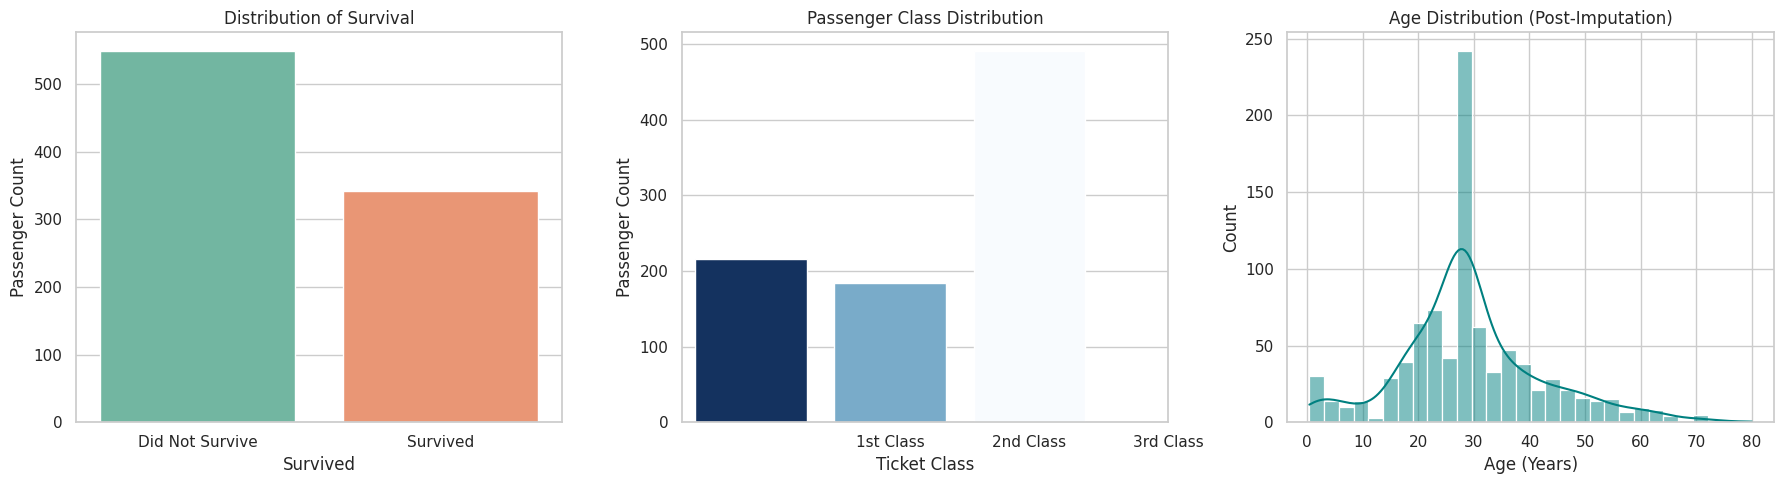

In [ ]:
# Overall Survival Rate
survival_rate = df['Survived'].mean() * 100
print(f"Overall Survival Rate: {survival_rate:.2f}%")

# Passenger Class Counts
pclass_counts = df['Pclass'].value_counts().sort_index()
print("\nPassenger Counts per Class:")
print(pclass_counts)
print(f"Class with the most passengers: {pclass_counts.idxmax()}rd Class ({pclass_counts.max()} passengers)")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Survival Count Plot
sns.countplot(
    data=df,
    x='Survived',
    hue='Survived',
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Distribution of Survival')
axes[0].set_xlabel('Survived')
axes[0].set_ylabel('Passenger Count')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Did Not Survive', 'Survived'])

# 2. Passenger Class Count Plot
sns.countplot(
    data=df,
    x='Pclass',
    hue='Pclass',
    palette='Blues_r',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Passenger Class Distribution')
axes[1].set_xlabel('Ticket Class')
axes[1].set_ylabel('Passenger Count')
axes[1].set_xticks([1, 2, 3])
axes[1].set_xticklabels(['1st Class', '2nd Class', '3rd Class'])

# 3. Age Distribution
sns.histplot(
    data=df,
    x='Age',
    bins=30,
    kde=True,
    color='teal',
    ax=axes[2]
)
axes[2].set_title('Age Distribution (Post-Imputation)')
axes[2].set_xlabel('Age (Years)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

Task 4: Bivariate & Multivariate Analysis

CROSSTAB: SEX VS SURVIVED
Survived    0    1  All
Sex                    
female     81  233  314
male      468  109  577
All       549  342  891

Survival Rate by Sex:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Survival Rate by Pclass:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

Survival Rate by Embarked:
Embarked
C    55.357143
Q    38.961039
S    33.900929
Name: Survived, dtype: float64


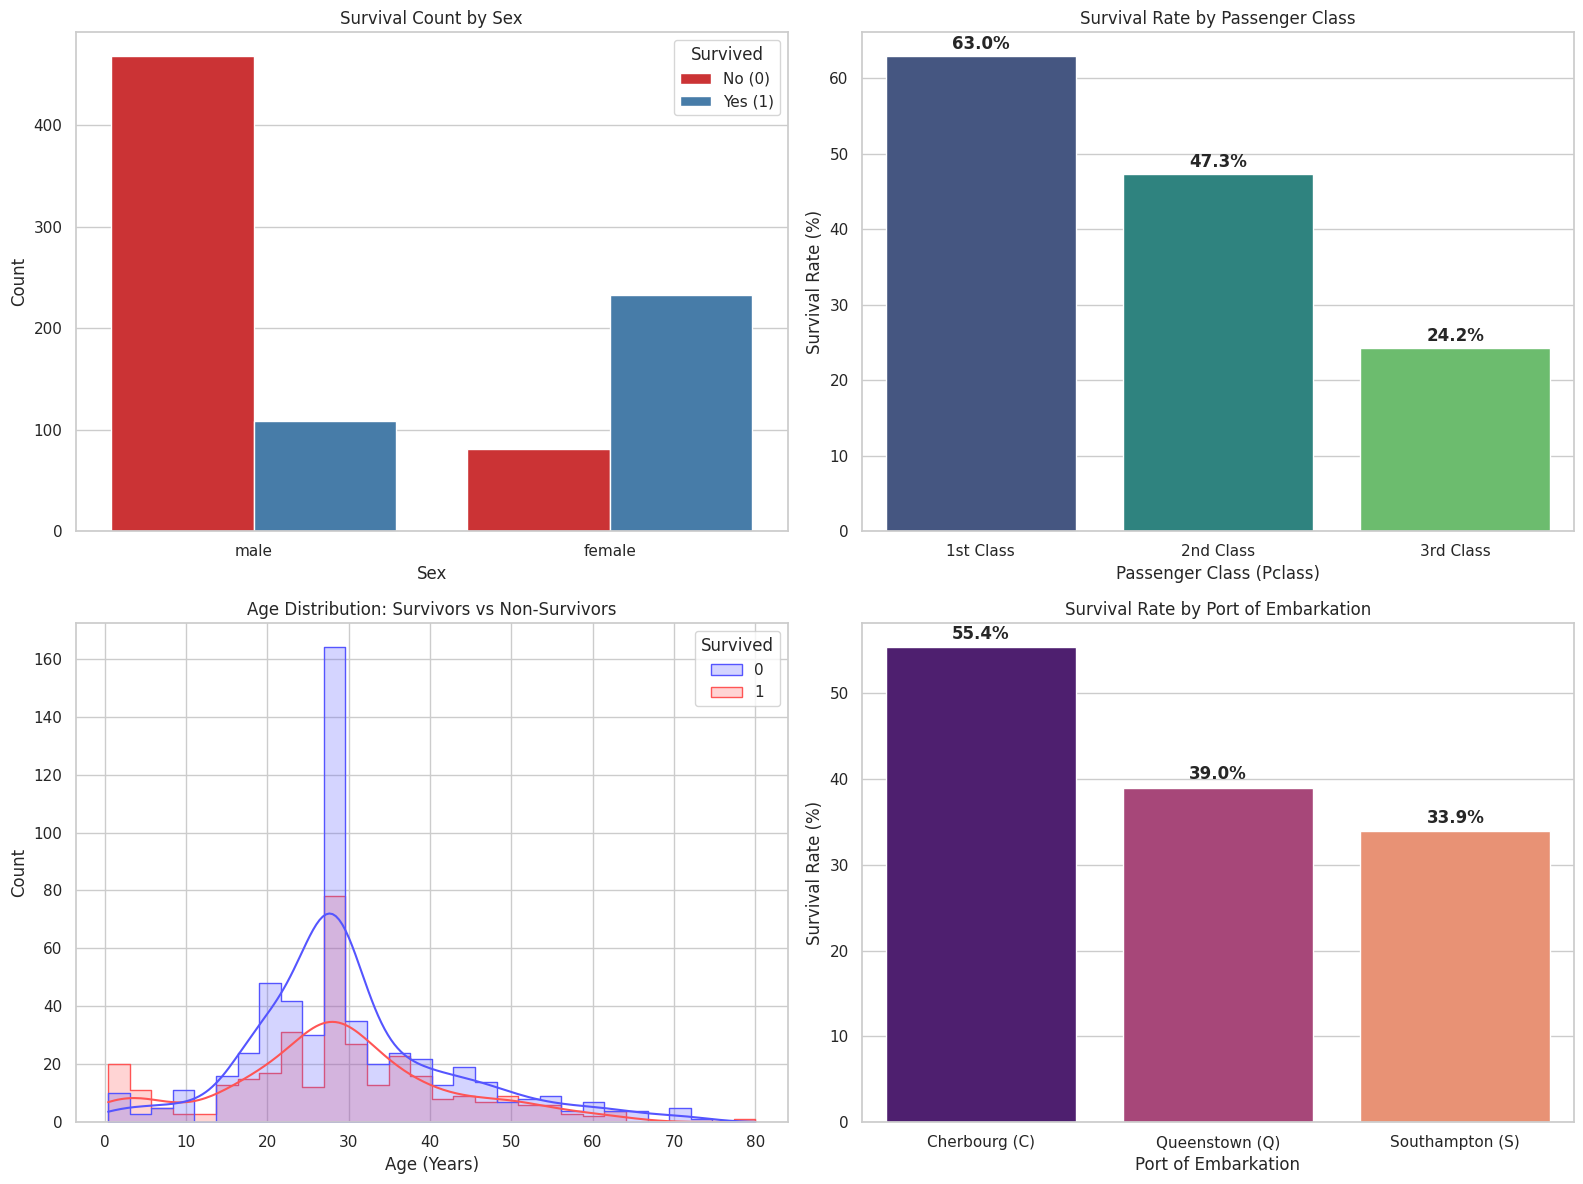

In [ ]:
# Survival by Sex

sex_crosstab = pd.crosstab(df['Sex'], df['Survived'], margins=True)
print("CROSSTAB: SEX VS SURVIVED")
print(sex_crosstab)

# Survival rates across different groupings

sex_surv_rate = df.groupby('Sex')['Survived'].mean() * 100
pclass_surv_rate = df.groupby('Pclass')['Survived'].mean() * 100
embarked_surv_rate = df.groupby('Embarked')['Survived'].mean() * 100

print(f"\nSurvival Rate by Sex:\n{sex_surv_rate}")
print(f"\nSurvival Rate by Pclass:\n{pclass_surv_rate}")
print(f"\nSurvival Rate by Embarked:\n{embarked_surv_rate}")

# Plotting Task 4 Relationships

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Survival by Sex

sns.countplot(
    data=df,
    x='Sex',
    hue='Survived',
    palette='Set1',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Survival Count by Sex')
axes[0, 0].set_xlabel('Sex')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend(title='Survived', labels=['No (0)', 'Yes (1)'])

# 2. Survival Rate by Passenger Class

sns.barplot(
    x=pclass_surv_rate.index.astype(str),
    y=pclass_surv_rate.values,
    hue=pclass_surv_rate.index.astype(str),
    palette='viridis',
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Survival Rate by Passenger Class')
axes[0, 1].set_xlabel('Passenger Class (Pclass)')
axes[0, 1].set_ylabel('Survival Rate (%)')
axes[0, 1].set_xticks([0, 1, 2])
axes[0, 1].set_xticklabels(['1st Class', '2nd Class', '3rd Class'])

for i, v in enumerate(pclass_surv_rate.values):
    axes[0, 1].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

# 3. Survival by Age

sns.histplot(
    data=df,
    x='Age',
    hue='Survived',
    kde=True,
    element='step',
    palette='seismic',
    common_norm=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Age Distribution: Survivors vs Non-Survivors')
axes[1, 0].set_xlabel('Age (Years)')
axes[1, 0].set_ylabel('Count')

# 4. Survival Rate by Embarked

sns.barplot(
    x=embarked_surv_rate.index,
    y=embarked_surv_rate.values,
    hue=embarked_surv_rate.index,
    palette='magma',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Survival Rate by Port of Embarkation')
axes[1, 1].set_xlabel('Port of Embarkation')
axes[1, 1].set_ylabel('Survival Rate (%)')
axes[1, 1].set_xticks([0, 1, 2])
axes[1, 1].set_xticklabels(['Cherbourg (C)', 'Queenstown (Q)', 'Southampton (S)'])

for i, v in enumerate(embarked_surv_rate.values):
    axes[1, 1].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

Task 5: Conclusion and Insights

In [ ]:
print("1. Sex: Female passengers had an approximately 74% survival rate, compared to about 19% for male passengers, indicating that the 'women and children first' policy was largely followed.")

print("2. Passenger Class: First-class passengers had an approximately 63% survival rate, whereas third-class passengers had only about a 24% survival rate, highlighting the impact of socio-economic status on survival.")

print("3. Age: Young children (under 10 years old) had relatively higher survival rates across all passenger classes, while elderly passengers experienced significantly higher mortality.")

1. Sex: Female passengers had an approximately 74% survival rate, compared to about 19% for male passengers, indicating that the 'women and children first' policy was largely followed.
2. Passenger Class: First-class passengers had an approximately 63% survival rate, whereas third-class passengers had only about a 24% survival rate, highlighting the impact of socio-economic status on survival.
3. Age: Young children (under 10 years old) had relatively higher survival rates across all passenger classes, while elderly passengers experienced significantly higher mortality.
